<div style="background: linear-gradient(120deg,#ffeef8 0%,#fecee6 32%,#c4dffc 72%,#9ecafe 100%);
            padding: 30px 36px; border-radius: 20px; border: 1px solid #fdc0e1;">
  <div style="font-size: 12px; letter-spacing: 3px; color: #6b5b70; text-transform: uppercase;">
    CISC7204 &middot; Data Visualization &middot; Course Project
  </div>
  <h1 style="margin: 8px 0 6px 0; color: #000000; font-size: 36px;">Breathing Unequal</h1>
  <div style="font-size: 17px; color: #3f3f4d; max-width: 900px;">
    Fifteen years of falling fine-particulate pollution &mdash; and the neighbourhoods it left behind &mdash;
    across New York City&rsquo;s 59 community districts (2009&ndash;2024)
  </div>
  <div style="margin-top: 14px; font-size: 13px; color: #5c5566;">
    Palette used throughout: <code>#fdc0e1 #fecee6 #ffeef8 #c4dffc #9ecafe #71b0fd</code>
  </div>
</div>

## 1. The question

**"New York City's air has become measurably cleaner since 2009 &mdash; but has it become cleaner *everywhere*?
Which community districts still carry the highest fine-particulate burden, what explains the gap,
and how many residents still breathe air above the World Health Organization guideline?"**

A precise, testable version of the question:

> Between 2009 and 2024, did the 59 community districts of New York City converge in annual mean
> PM2.5 concentration, and is the remaining variation explained by traffic density and co-pollutants
> rather than by borough identity alone?

The project is deliberately *descriptive and spatial* rather than causal: the aim is to show, with
honest visual evidence, where a citywide improvement has and has not reached.

### Why this question matters

PM2.5 particles are small enough to reach the alveoli and are linked to asthma, cardiovascular
events and premature death. A citywide average can improve while the districts with the most
vulnerable residents stay at the top of the distribution &mdash; a pattern that is invisible in a
single headline number but obvious once the data are plotted by neighbourhood.

### Short statement: how the visualisations answer the question

The notebook answers the question in three visual steps. First, a population-weighted time series shows
that the citywide annual mean fell from about 10.9 to 6.5 &micro;g/m&sup3; between 2009 and 2024, with a
sharp dip in the pandemic year and a new low in 2022 before a small rebound. Second, a paired district chart shows that this
improvement was **not uniform**: the cleanest districts improved faster in relative terms, so the ratio
between the dirtiest and the cleanest district widened slightly (1.84&times; in 2009, 1.99&times; in 2024),
and every one of the 59 districts is still above the WHO 2024 guideline of 5 &micro;g/m&sup3;. Third,
scatter plots tie the remaining spatial pattern to traffic: district PM2.5 tracks traffic density
(r &asymp; 0.62 in 2019) and NO&#8322; almost perfectly (r &asymp; 0.90 in 2024), which is the signature of
road traffic rather than of geography. Together the three views convert a single improving average into
a statement about *who* is still exposed.

## 2. Data

Both datasets are open government data published by the City of New York through the
[NYC Open Data](https://opendata.cityofnewyork.us/) portal (part of the [data.gov](https://www.data.gov/)
network). They were downloaded on **2026-10-21** by `download_data.py` in the project folder, so the
analysis runs offline from `data/`.

| # | Dataset | Publisher | Link | Size used |
|---|---|---|---|---|
| 1 | **Air Quality and Health Impacts** (`c3uy-2p5r`) | NYC Department of Health and Mental Hygiene | <https://data.cityofnewyork.us/Environment/Air-Quality-and-Health-Impacts/c3uy-2p5r> | 7,257 rows (community districts) + 910 rows (boroughs) |
| 2 | **New York City Population by Community Districts** (`xi7c-iiu2`) | NYC Department of City Planning | <https://data.cityofnewyork.us/City-Government/New-York-City-Population-By-Community-Districts/xi7c-iiu2> | 59 rows (one per district) |

Dataset 1 is the analytical core: it publishes annual mean PM2.5 by community district for 2009&ndash;2024,
plus NO&#8322;, ozone, benzene, formaldehyde and traffic density, and a set of modelled health-impact
indicators (asthma emergency-department visits, hospitalisations, deaths attributable to PM2.5) that are
only published at *borough* level. Dataset 2 supplies the population weights needed to turn concentrations
into exposure.

**Known limitation, stated up front:** the population file is the Census series ending in 2010, because a
community-district population table with later vintages is not published on the portal. Population weights
are therefore treated as a stable proxy for the *relative* size of districts, not as a current count.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# The palette requested for this project: three pinks and three blues.
# ---------------------------------------------------------------------------
PINK_LIGHT, PINK_MID, PINK_PALE = "#fdc0e1", "#fecee6", "#ffeef8"
BLUE_LIGHT, BLUE_MID, BLUE_DEEP = "#c4dffc", "#9ecafe", "#71b0fd"
INK = "#2f2f3a"
MUTED = "#6b6473"
GRID = "#efe3ec"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fffdfe",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.titlecolor": "#000000",
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10.5,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.bbox": "tight",
})

# Sequential "pink -> blue" map for continuous values, and a categorical map for boroughs
SEQ = LinearSegmentedColormap.from_list("pink_blue", [PINK_PALE, PINK_MID, PINK_LIGHT, BLUE_LIGHT, BLUE_MID, BLUE_DEEP])
BOROUGH_COLOR = {
    "Manhattan": BLUE_DEEP,
    "Brooklyn": BLUE_MID,
    "Queens": BLUE_LIGHT,
    "Bronx": PINK_LIGHT,
    "Staten Island": PINK_MID,
}
BOROUGH_ORDER = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
BOROUGH_CODE = {"Manhattan": 1, "Bronx": 2, "Brooklyn": 3, "Queens": 4, "Staten Island": 5}

DATA = Path("data")
print("pandas", pd.__version__, "| matplotlib", mpl.__version__)
print("data files:", sorted(p.name for p in DATA.glob("*.csv")))

pandas 2.2.3 | matplotlib 3.10.0
data files: ['air_quality_borough.csv', 'air_quality_cd.csv', 'population_cd.csv']


## 3. Preparing the data

The air-quality table is stored in long format (one row per indicator &times; geography &times; period).
Three filters turn it into the analysis table:

1. `geo_type_name == "CD"` keeps the 59 community districts (borough and citywide rows are kept separately
   for the health comparison);
2. `name == "Fine particles (PM 2.5)"` and `measure == "Annual mean"` keep the annual PM2.5 series;
3. `time_period` is converted to an integer year.

The first two digits of a community-district code encode the borough (`101` = Manhattan CD 1,
`205` = Bronx CD 5, and so on), which lets the population file be joined on a single key.

In [2]:
def load_long(path):
    df = pd.read_csv(path)
    df["value"] = pd.to_numeric(df["data_value"], errors="coerce")
    df["year"] = pd.to_numeric(df["time_period"], errors="coerce")
    df["cd"] = pd.to_numeric(df["geo_join_id"], errors="coerce")
    return df


cd_long = load_long(DATA / "air_quality_cd.csv")
borough_long = load_long(DATA / "air_quality_borough.csv")

pm25 = (
    cd_long.query("name == 'Fine particles (PM 2.5)' and measure == 'Annual mean'")
    .dropna(subset=["cd", "year", "value"])
    .assign(
        cd=lambda d: d["cd"].astype(int),
        year=lambda d: d["year"].astype(int),
        borough=lambda d: (d["cd"] // 100).map({v: k for k, v in BOROUGH_CODE.items()}),
        district=lambda d: d["geo_place_name"].str.replace(r"\s*\(CD\d+\)$", "", regex=True),
    )[["cd", "district", "borough", "year", "value"]]
    .rename(columns={"value": "pm25"})
)

pm25 = pm25[pm25["year"].between(2009, 2024)]

population = pd.read_csv(DATA / "population_cd.csv")
population["cd"] = population["borough"].map(BOROUGH_CODE) * 100 + population["cd_number"]
population["pop2010"] = pd.to_numeric(population["_2010_population"], errors="coerce")

panel = pm25.merge(population[["cd", "pop2010"]], on="cd", how="left")

print("PM2.5 panel:", panel.shape, "| districts:", panel.cd.nunique(), "| years:",
      panel.year.min(), "-", panel.year.max())
print("missing population weights:", int(panel.pop2010.isna().sum()))
panel.head()

PM2.5 panel: (944, 6) | districts: 59 | years: 2009 - 2024
missing population weights: 0


,cd,district,borough,year,pm25,pop2010
0,101,Financial District,Manhattan,2009,13.05,60978
1,102,Greenwich Village and Soho,Manhattan,2009,12.82,90016
2,103,Lower East Side and Chinatown,Manhattan,2009,11.85,163277
3,104,Clinton and Chelsea,Manhattan,2009,13.22,103245
4,105,Midtown,Manhattan,2009,16.09,51673


## 4. Setting the scene: a cleaner city

The first view is the one a press release would show. Each thin line is one community district; the
thick line is the **population-weighted** city mean, so it reflects what a typical resident breathes
rather than what an unweighted average of neighbourhoods reports. The 2020 band marks the pandemic year,
when traffic collapsed and the annual mean dropped to its lowest point in the series.

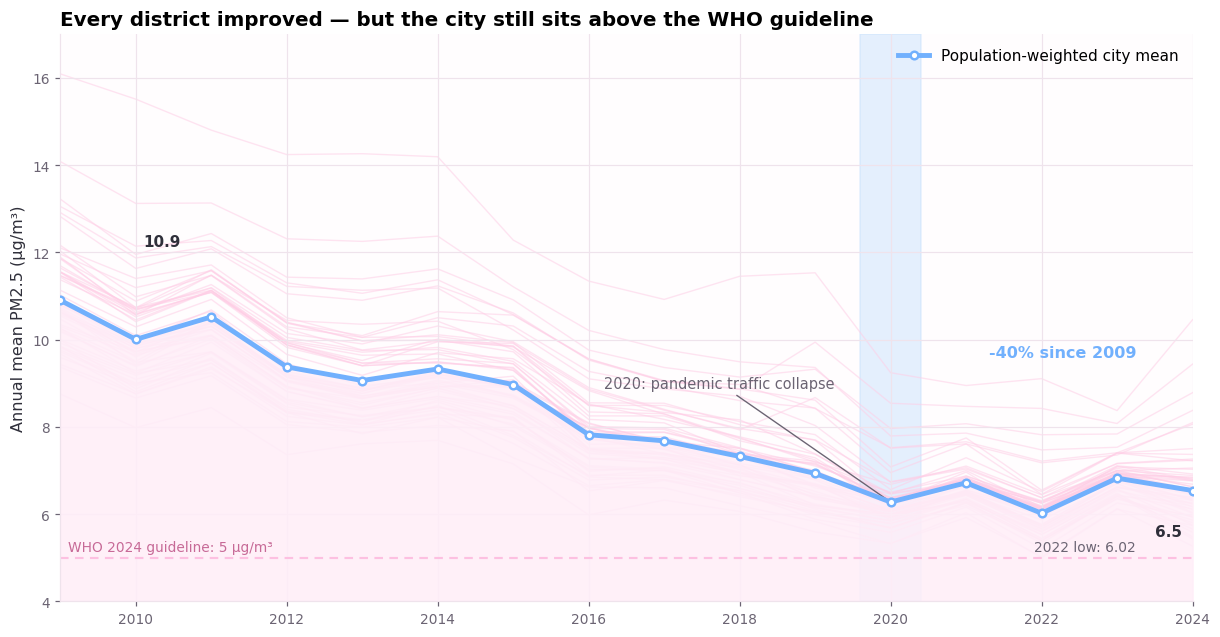

Citywide weighted mean 2009: 10.90 µg/m³ | 2024: 6.54 µg/m³ | change -4.36
Districts above the WHO guideline in 2024: 59 of 59


In [3]:
city = (
    panel.groupby("year")
    .apply(lambda g: np.average(g["pm25"], weights=g["pop2010"]), include_groups=False)
    .rename("weighted_mean")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11.2, 5.9))

for _, g in panel.groupby("cd"):
    ax.plot(g["year"], g["pm25"], color=PINK_MID, linewidth=0.9, alpha=0.55, zorder=1)

ax.fill_between(city["year"], city["weighted_mean"], color=PINK_PALE, alpha=0.85, zorder=2)
ax.plot(city["year"], city["weighted_mean"], color=BLUE_DEEP, linewidth=3.2, marker="o", markersize=5,
        markerfacecolor="white", markeredgewidth=1.6, zorder=4, label="Population-weighted city mean")

ax.axvspan(2019.6, 2020.4, color=BLUE_LIGHT, alpha=0.45, zorder=0)
ax.annotate("2020: pandemic traffic collapse", xy=(2020, city.loc[city.year == 2020, "weighted_mean"].iat[0]),
            xytext=(2016.2, 8.9), fontsize=9.5, color=MUTED,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.9))

start = city.loc[city.year == 2009, "weighted_mean"].iat[0]
end = city.loc[city.year == 2024, "weighted_mean"].iat[0]
ax.annotate(f"{start:.1f}", xy=(2009, start), xytext=(2010.1, start + 1.25), fontsize=10, color=INK, fontweight="bold")
ax.annotate(f"{end:.1f}", xy=(2024, end), xytext=(2023.5, end - 1.05), fontsize=10, color=INK, fontweight="bold")
ax.annotate(f"{(end - start) / start:+.0%} since 2009", xy=(2024, end), xytext=(2021.3, 9.6),
            fontsize=10.5, color=BLUE_DEEP, fontweight="bold")
ax.annotate("2022 low: 6.02", xy=(2022, city.loc[city.year == 2022, "weighted_mean"].iat[0]),
            xytext=(2021.9, 5.15), fontsize=9, color=MUTED)

ax.axhline(5, color=PINK_LIGHT, linestyle=(0, (4, 3)), linewidth=1.4)
ax.text(2009.1, 5.15, "WHO 2024 guideline: 5 µg/m³", fontsize=9, color="#c76a97")

ax.set_xlim(2009, 2024)
ax.set_ylim(4, 17)
ax.set_xlabel("")
ax.set_ylabel("Annual mean PM2.5 (µg/m³)")
ax.set_title("Every district improved — but the city still sits above the WHO guideline", loc="left")
ax.legend(loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Citywide weighted mean 2009: {start:.2f} µg/m³ | 2024: {end:.2f} µg/m³ | change {end-start:+.2f}")
print(f"Districts above the WHO guideline in 2024: {(panel.loc[panel.year == 2024, 'pm25'] > 5).sum()} of 59")

## 5. Where the air is still worst

The average hides the geography. The chart below pairs each district's 2009 value with its 2024 value.
Districts are ordered by their 2024 concentration, so the top of the chart is where the burden remains;
the length of each connector shows how much that district improved. Colour encodes the borough.

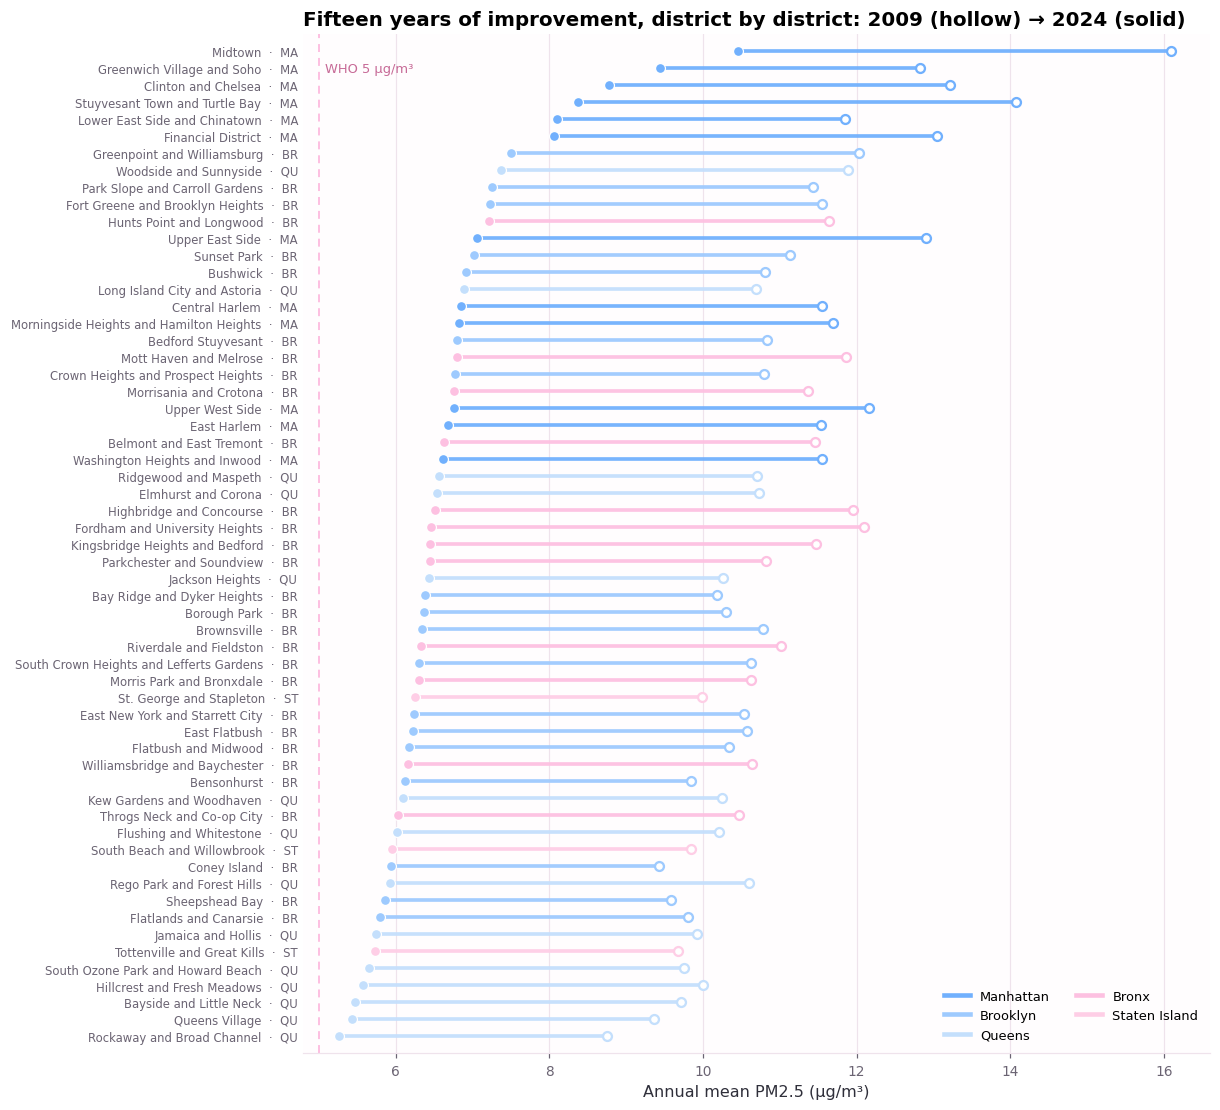

Highest 2024 concentrations:
                   district_24 borough_24   pm25_24
                       Midtown  Manhattan 10.453383
    Greenwich Village and Soho  Manhattan  9.436341
           Clinton and Chelsea  Manhattan  8.782177
Stuyvesant Town and Turtle Bay  Manhattan  8.375132
 Lower East Side and Chinatown  Manhattan  8.095915

Largest percentage reductions:
                   district_24  pm25_09  pm25_24  drop_pct
Fordham and University Heights     12.1      6.5      46.6
      Highbridge and Concourse     12.0      6.5      45.6
               Upper East Side     12.9      7.1      45.3
               Upper West Side     12.2      6.8      44.4
   Hillcrest and Fresh Meadows     10.0      5.6      44.2


In [4]:
w09 = panel[panel.year == 2009].set_index("cd")[["pm25", "district", "borough"]].add_suffix("_09")
w24 = panel[panel.year == 2024].set_index("cd")[["pm25", "district", "borough"]].add_suffix("_24")
shift = w09.join(w24).reset_index()
shift["drop_pct"] = (shift["pm25_09"] - shift["pm25_24"]) / shift["pm25_09"] * 100
shift = shift.sort_values("pm25_24", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11.2, 10.2))

for i, row in shift.iterrows():
    colour = BOROUGH_COLOR[row["borough_24"]]
    ax.plot([row["pm25_09"], row["pm25_24"]], [i, i], color=colour, linewidth=2.4, solid_capstyle="round", alpha=0.95)
    ax.scatter(row["pm25_09"], i, s=34, facecolor="white", edgecolor=colour, linewidth=1.5, zorder=3)
    ax.scatter(row["pm25_24"], i, s=42, color=colour, edgecolor="white", linewidth=0.8, zorder=4)

ax.set_yticks(range(len(shift)))
ax.set_yticklabels([f"{r.district_24}  ·  {r.borough_24[:2].upper()}" for r in shift.itertuples()], fontsize=7.6)
ax.set_ylim(-1, len(shift))
ax.set_xlim(4.8, 16.6)
ax.set_xlabel("Annual mean PM2.5 (µg/m³)")
ax.set_title("Fifteen years of improvement, district by district: 2009 (hollow) → 2024 (solid)", loc="left")
ax.xaxis.grid(True)
ax.yaxis.grid(False)

ax.axvline(5, color=PINK_LIGHT, linestyle=(0, (4, 3)), linewidth=1.3)
ax.text(5.08, len(shift) - 2.2, "WHO 5 µg/m³", fontsize=8.5, color="#c76a97")

handles = [Line2D([0], [0], color=BOROUGH_COLOR[b], linewidth=3, label=b) for b in BOROUGH_ORDER]
ax.legend(handles=handles, loc="lower right", ncol=2, fontsize=8.5)

for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

print("Highest 2024 concentrations:")
print(shift.sort_values("pm25_24", ascending=False)[["district_24", "borough_24", "pm25_24"]].head(5).to_string(index=False))
print("\nLargest percentage reductions:")
print(shift.sort_values("drop_pct", ascending=False)[["district_24", "pm25_09", "pm25_24", "drop_pct"]].head(5).round(1).to_string(index=False))

## 6. Did the districts converge?

If the improvement had been shared evenly, the spread across districts would shrink. Two measures
tell us whether that happened: the standard deviation of district concentrations (absolute spread) and
the coefficient of variation, SD &divide; mean (relative spread). They disagree &mdash; which is exactly
the point: the gap in *micrograms* shrank because every district improved, but the gap in *proportional*
terms did not.

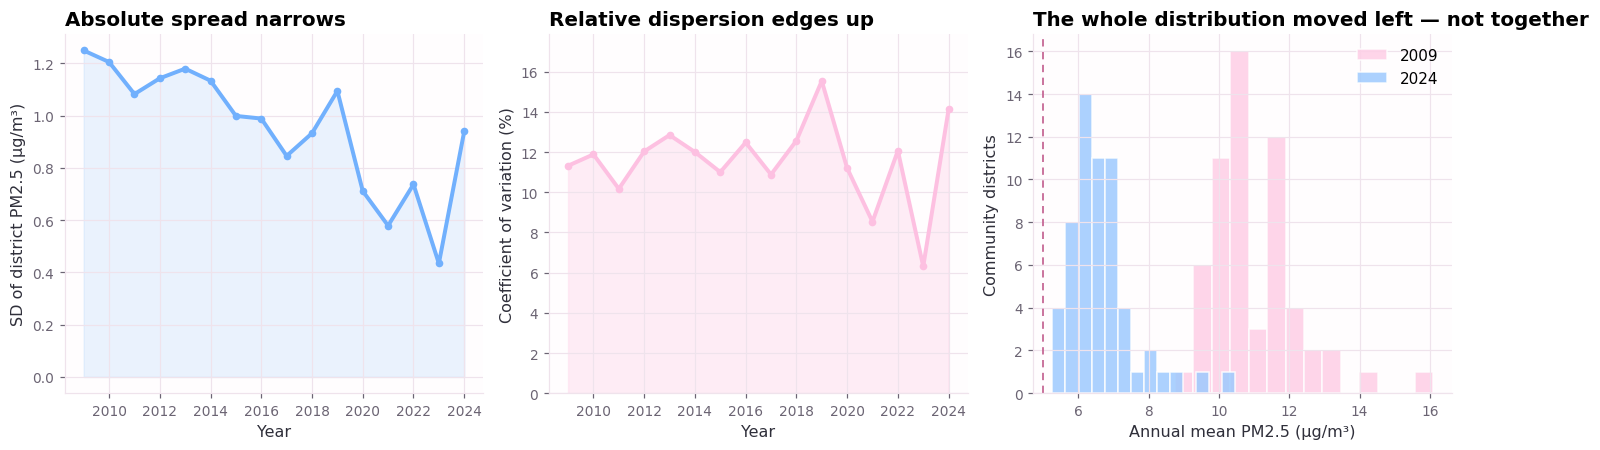

SD 2009 1.25 -> 2024 0.94
CV 2009 11.3% -> 2024 14.1%
Note: 2023 is unusually compressed (max/min 1.37) — see the data-quality note below.


In [5]:
spread = (
    panel.groupby("year")["pm25"]
    .agg(mean="mean", sd="std", lowest="min", highest="max")
    .assign(cv=lambda d: d["sd"] / d["mean"] * 100)
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.2))

axes[0].plot(spread["year"], spread["sd"], color=BLUE_DEEP, linewidth=2.6, marker="o", markersize=4)
axes[0].fill_between(spread["year"], spread["sd"], color=BLUE_LIGHT, alpha=0.35)
axes[0].set_title("Absolute spread narrows", loc="left")
axes[0].set_ylabel("SD of district PM2.5 (µg/m³)")

axes[1].plot(spread["year"], spread["cv"], color=PINK_LIGHT, linewidth=2.6, marker="o", markersize=4)
axes[1].fill_between(spread["year"], spread["cv"], color=PINK_MID, alpha=0.35)
axes[1].set_title("Relative dispersion edges up", loc="left")
axes[1].set_ylabel("Coefficient of variation (%)")
axes[1].set_ylim(0, max(spread["cv"].max() * 1.15, 16))

axes[2].hist(w09["pm25_09"], bins=14, color=PINK_MID, alpha=0.85, label="2009", edgecolor="white")
axes[2].hist(w24["pm25_24"], bins=14, color=BLUE_MID, alpha=0.85, label="2024", edgecolor="white")
axes[2].axvline(5, color="#c76a97", linestyle=(0, (4, 3)), linewidth=1.2)
axes[2].set_title("The whole distribution moved left — not together", loc="left")
axes[2].set_xlabel("Annual mean PM2.5 (µg/m³)")
axes[2].set_ylabel("Community districts")
axes[2].legend(loc="upper right")

for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel("Year") if ax is not axes[2] else None

plt.tight_layout()
plt.show()

print(f"SD 2009 {spread.loc[spread.year == 2009, 'sd'].iat[0]:.2f} -> 2024 {spread.loc[spread.year == 2024, 'sd'].iat[0]:.2f}")
print(f"CV 2009 {spread.loc[spread.year == 2009, 'cv'].iat[0]:.1f}% -> 2024 {spread.loc[spread.year == 2024, 'cv'].iat[0]:.1f}%")
print("Note: 2023 is unusually compressed (max/min 1.37) — see the data-quality note below.")

## 7. What explains the remaining pattern?

Two candidates are available in the same dataset: **traffic density** (million vehicle-miles per district)
and **nitrogen dioxide**, a gas that is emitted almost entirely by combustion engines and is therefore a
good marker of local road traffic. If both line up with PM2.5 district by district, the residual pattern
is best read as a traffic pattern rather than as a coincidence of geography.

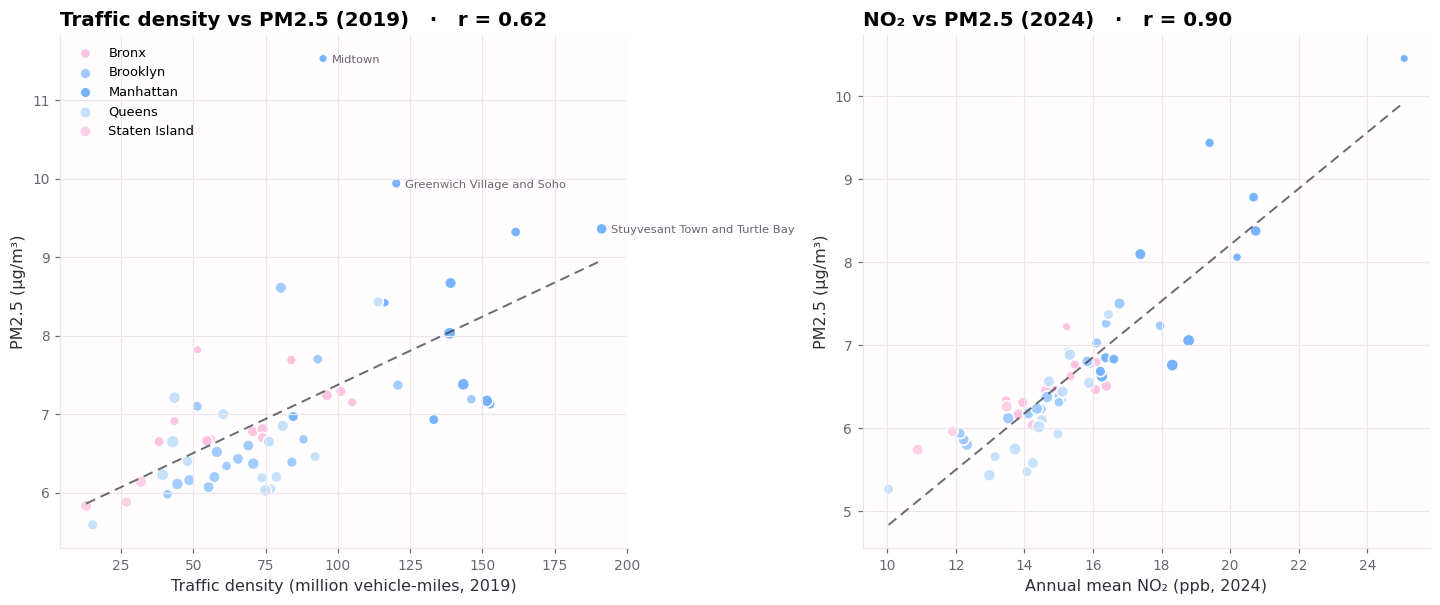

Traffic density vs PM2.5 (2019): r = 0.615  (n=59)
NO2 vs PM2.5 (2024):            r = 0.903  (n=59)


In [6]:
traffic = (
    cd_long.query("name == 'Traffic density' and measure == 'Million miles'")
    .dropna(subset=["cd", "year", "value"])
    .assign(cd=lambda d: d["cd"].astype(int), year=lambda d: d["year"].astype(int))
    .groupby(["cd", "year"], as_index=False)["value"].mean()
    .rename(columns={"value": "traffic"})
)

no2 = (
    cd_long.query("name == 'Nitrogen dioxide (NO2)' and measure == 'Annual mean'")
    .dropna(subset=["cd", "year", "value"])
    .assign(cd=lambda d: d["cd"].astype(int), year=lambda d: d["year"].astype(int))
    .rename(columns={"value": "no2"})
)

t19 = traffic[traffic.year == 2019][["cd", "traffic"]]
p19 = panel[panel.year == 2019][["cd", "district", "borough", "pm25", "pop2010"]]
traffic_panel = p19.merge(t19, on="cd")

n24 = no2[no2.year == 2024][["cd", "no2"]]
p24 = panel[panel.year == 2024][["cd", "district", "borough", "pm25", "pop2010"]]
no2_panel = p24.merge(n24, on="cd")

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.6))

for ax, frame, xcol, xlabel, title in [
    (axes[0], traffic_panel, "traffic", "Traffic density (million vehicle-miles, 2019)", "Traffic density vs PM2.5 (2019)"),
    (axes[1], no2_panel, "no2", "Annual mean NO₂ (ppb, 2024)", "NO₂ vs PM2.5 (2024)"),
]:
    for borough, g in frame.groupby("borough"):
        ax.scatter(g[xcol], g["pm25"], s=np.sqrt(g["pop2010"]) / 7, color=BOROUGH_COLOR[borough],
                   edgecolor="white", linewidth=1.1, alpha=0.95, label=borough)
    slope, intercept = np.polyfit(frame[xcol], frame["pm25"], 1)
    xs = np.linspace(frame[xcol].min(), frame[xcol].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK, linewidth=1.3, linestyle=(0, (5, 3)), alpha=0.7)
    r = frame[xcol].corr(frame["pm25"])
    ax.set_title(f"{title}   ·   r = {r:.2f}", loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("PM2.5 (µg/m³)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].legend(loc="upper left", fontsize=8.5)
for row in traffic_panel.nlargest(3, "pm25").itertuples():
    axes[0].annotate(row.district, (row.traffic, row.pm25), xytext=(6, -3), textcoords="offset points",
                     fontsize=7.5, color=MUTED)

plt.tight_layout()
plt.show()

print(f"Traffic density vs PM2.5 (2019): r = {traffic_panel.traffic.corr(traffic_panel.pm25):.3f}  (n={len(traffic_panel)})")
print(f"NO2 vs PM2.5 (2024):            r = {no2_panel.no2.corr(no2_panel.pm25):.3f}  (n={len(no2_panel)})")

## 8. Exposure: how many people are still affected?

Concentrations are not the same as exposure. Weighting each district by its population converts the
map into a statement about residents: what the average New Yorker breathes, and how much of the
population lives in districts above the WHO guideline.

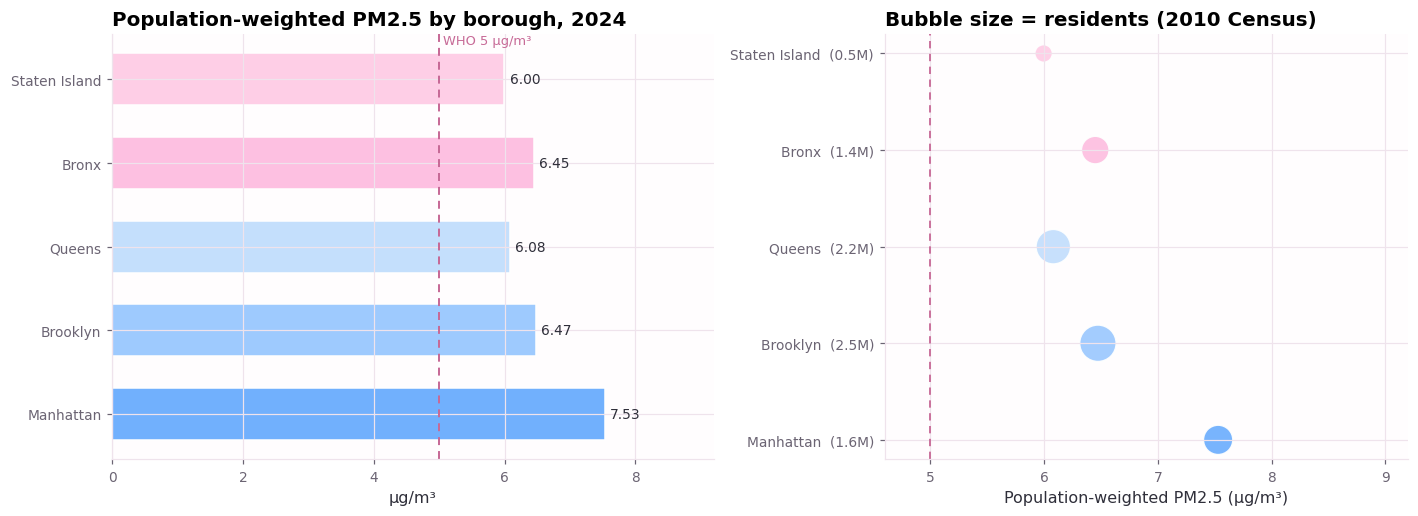

Residents in districts above the WHO guideline: 8.17M of 8.17M (100%)
Districts above the guideline: 59 of 59
Lowest district value in 2024: 5.26 µg/m³


In [7]:
expo = panel[panel.year == 2024].copy()
expo["above_who"] = expo["pm25"] > 5

by_borough = (
    expo.groupby("borough")
    .apply(lambda g: pd.Series({
        "population": g["pop2010"].sum(),
        "weighted_pm25": np.average(g["pm25"], weights=g["pop2010"]),
        "share_above": np.average(g["above_who"], weights=g["pop2010"]) * 100,
    }), include_groups=False)
    .reindex(BOROUGH_ORDER)
)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})

bars = axes[0].barh(by_borough.index, by_borough["weighted_pm25"],
                    color=[BOROUGH_COLOR[b] for b in by_borough.index], edgecolor="white", height=0.62)
axes[0].axvline(5, color="#c76a97", linestyle=(0, (4, 3)), linewidth=1.3)
axes[0].text(5.06, 4.42, "WHO 5 µg/m³", fontsize=8.5, color="#c76a97")
for bar, value in zip(bars, by_borough["weighted_pm25"]):
    axes[0].text(value + 0.08, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center",
                 fontsize=9, color=INK)
axes[0].set_xlim(0, 9.2)
axes[0].set_title("Population-weighted PM2.5 by borough, 2024", loc="left")
axes[0].set_xlabel("µg/m³")

sizes = by_borough["population"] / 1e6
axes[1].scatter(by_borough["weighted_pm25"], range(len(by_borough)), s=sizes * 220 + 40,
                color=[BOROUGH_COLOR[b] for b in by_borough.index], edgecolor="white", linewidth=1.4, alpha=0.95)
axes[1].set_yticks(range(len(by_borough)))
axes[1].set_yticklabels([f"{b}  ({p:.1f}M)" for b, p in zip(by_borough.index, sizes)])
axes[1].axvline(5, color="#c76a97", linestyle=(0, (4, 3)), linewidth=1.2)
axes[1].set_xlim(4.6, 9.2)
axes[1].set_xlabel("Population-weighted PM2.5 (µg/m³)")
axes[1].set_title("Bubble size = residents (2010 Census)", loc="left")

for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

total = expo["pop2010"].sum()
above = expo.loc[expo["above_who"], "pop2010"].sum()
print(f"Residents in districts above the WHO guideline: {above/1e6:.2f}M of {total/1e6:.2f}M ({above/total:.0%})")
print(f"Districts above the guideline: {int(expo['above_who'].sum())} of {len(expo)}")
print(f"Lowest district value in 2024: {expo['pm25'].min():.2f} µg/m³")

## 9. A borough-level cross-check with health outcomes

The air-quality dataset also publishes modelled health impacts, but only at borough level: five points,
which is far too few for a strong inference. The comparison is included as a **descriptive cross-check**,
not as evidence of causation. Asthma emergency-department visits for children are highest in the Bronx,
which is *not* the borough with the highest PM2.5 &mdash; a reminder that exposure, housing quality,
poverty and access to care all contribute.

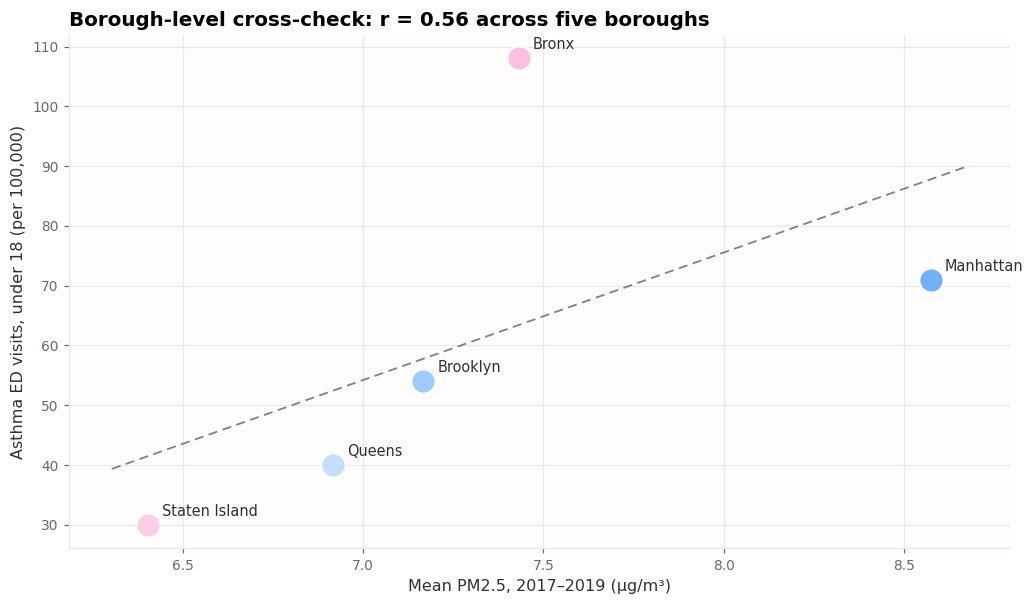

      borough  pm25  asthma_ed_u18
        Bronx   7.4          108.0
    Manhattan   8.6           71.0
     Brooklyn   7.2           54.0
       Queens   6.9           40.0
Staten Island   6.4           30.0


In [8]:
asthma = (
    borough_long.query("name == 'Asthma emergency department visits due to PM2.5'"
                       " and measure == 'Estimated annual rate (under age 18)'")
    .dropna(subset=["value"])
    .rename(columns={"geo_place_name": "borough", "value": "asthma_ed_u18"})
)

asthma_period = "2017-2019"
asthma_now = asthma[asthma["time_period"] == asthma_period][["borough", "asthma_ed_u18"]]
borough_pm = panel[panel.year.between(2017, 2019)].groupby("borough", as_index=False)["pm25"].mean()
health = borough_pm.merge(asthma_now, on="borough").sort_values("asthma_ed_u18", ascending=True)

fig, ax = plt.subplots(figsize=(9.6, 5.6))
for row in health.itertuples():
    ax.scatter(row.pm25, row.asthma_ed_u18, s=260, color=BOROUGH_COLOR[row.borough],
               edgecolor="white", linewidth=1.6, zorder=3)
    ax.annotate(row.borough, (row.pm25, row.asthma_ed_u18), xytext=(9, 6), textcoords="offset points",
                fontsize=9.5, color=INK)

r_health = health.pm25.corr(health.asthma_ed_u18)
slope, intercept = np.polyfit(health.pm25, health.asthma_ed_u18, 1)
xs = np.linspace(health.pm25.min() - 0.1, health.pm25.max() + 0.1, 20)
ax.plot(xs, slope * xs + intercept, color=INK, linestyle=(0, (5, 3)), linewidth=1.2, alpha=0.6, zorder=2)

ax.set_xlabel("Mean PM2.5, 2017–2019 (µg/m³)")
ax.set_ylabel("Asthma ED visits, under 18 (per 100,000)")
ax.set_title(f"Borough-level cross-check: r = {r_health:.2f} across five boroughs", loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

print(health.sort_values("asthma_ed_u18", ascending=False).round(1).to_string(index=False))

## 10. What the data say

**1. The city got cleaner.** The population-weighted annual mean fell from **10.90 to 6.54 µg/m³** between 2009 and 2024,
a reduction of **40%**. The pandemic year dipped to 6.27 µg/m³, 2022 set the series low at 6.02, and
2023&ndash;24 drifted back up to about 6.7.

**2. The improvement did not reach everywhere equally.** The absolute spread across districts narrowed
(SD 1.25 &rarr; 0.94 µg/m³), but relative dispersion did not improve: the coefficient of variation was
11.3% in 2009 and 14.1% in 2024, having oscillated between 6% and 16% in between, and the
dirtiest-to-cleanest ratio moved from 1.84&times; to 1.99&times;. Districts that
started low improved proportionally faster, so the *rank* of districts is stickier than the level.

**3. The burden is concentrated in the central business districts.** Midtown (10.45 µg/m³), Greenwich
Village/Soho (9.44) and Clinton/Chelsea (8.78) remain the highest in 2024; the Rockaways (5.26),
Queens Village (5.43) and Bayside (5.48) are the lowest. Manhattan's districts still average
**7.83 µg/m³** (7.53 population-weighted), about 30% above Staten Island's 5.99.

**4. Traffic is the visible driver.** District PM2.5 correlates with traffic density at r &asymp; 0.62
(2019) and with NO&#8322; at r &asymp; 0.90 (2024), so the spatial residue looks like a road-traffic
signature rather than an arbitrary geographic one.

**5. The WHO guideline is still out of reach.** All **59** districts were above 5 µg/m³ in 2024; the
cleanest district is only 5% above it. In population terms, every resident counted in this analysis
lives in a district above the guideline.

**6. Pollution is not the whole health story.** Borough-level asthma emergency-department rates for
children are highest in the Bronx (108 per 100,000) even though Manhattan has the highest PM2.5,
and the five-point correlation is only r &asymp; 0.56. With five observations this is not a test of
association; it is a warning that air quality and health vulnerability are different maps.

## 11. Limitations and what I would do next

- **Ecological design.** Everything here is measured at district or borough level; no individual-level
  exposure or health data are used, so no causal claim about individuals is possible.
- **Population vintage.** Exposure weights come from the 2010 Census because a later community-district
  table is not published on the portal. The *relative* ranking of districts is stable, but the absolute
  number of residents above the guideline is indicative only.
- **Modelled health indicators.** The asthma, hospitalisation and mortality figures are modelled
  estimates published by the health department, not raw counts.
- **Traffic density is sparse.** It is available for 2005, 2010 and 2019 only, so the traffic analysis is
  a single cross-section rather than a trend.
- **A data-quality flag on 2023.** The 2023 cross-section is much flatter than its neighbours (district
  range 6.11&ndash;8.37 µg/m³, max/min 1.37) while 2022 and 2024 are wider again. This looks like a change in
  the modelling or averaging vintage rather than a real one-year flattening, so year-on-year ratios around
  2023 are reported but not interpreted.
- **Next steps.** Join the US EPA's national PM2.5 monitors for an independent measurement series;
  bring in ACS income and housing data by district to test whether the burden tracks deprivation;
  and use a spatial lag model to check whether the pattern is diffusion rather than local emissions.

## 12. References

1. NYC Department of Health and Mental Hygiene, *Air Quality and Health Impacts*, NYC Open Data,
   dataset `c3uy-2p5r`, accessed 2026-10-21.
2. NYC Department of City Planning, *New York City Population by Community Districts*, NYC Open Data,
   dataset `xi7c-iiu2`, accessed 2026-10-21.
3. World Health Organization (2021), *WHO global air quality guidelines: particulate matter (PM2.5 and
   PM10), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide*. Geneva: WHO.
4. US Environmental Protection Agency, *Particulate Matter (PM) Basics*, <https://www.epa.gov/pm-pollution>.

## Appendix A — Project proposal (per the course proposal guideline)

**Project title.** *Breathing Unequal: Has New York City's Air-Quality Improvement Reached Every
Neighbourhood?*

**Guiding question.** Between 2009 and 2024, did the 59 community districts of New York City converge in
annual mean PM2.5, and is the remaining variation explained by traffic density and co-pollutants rather
than by borough identity?

**Purpose.**
*Outcomes* — connects the course's data-visualisation outcomes (choosing an appropriate encoding for a
quantitative spatial question, designing small multiples and paired charts, and writing a narrative
around evidence) to a public-policy question in environmental health.
*Skills* — API-based data acquisition from an open-data portal, tidy-data reshaping of a long-format
indicator table, weighting, correlation and simple regression, and iterative visual design with a
restricted palette.
*Knowledge* — air-quality indicators (PM2.5, NO&#8322;), the WHO 2021 guideline values, the ecological
fallacy, and the difference between concentration and population exposure.

**Tasks.**
1. Download the two datasets from NYC Open Data and store them locally with a reproducible script.
2. Reshape the long indicator table into a district &times; year panel and join population weights.
3. Produce four analytical views: citywide trend, paired district change, inequality measures, and
   traffic/co-pollutant scatters.
4. Quantify exposure and cross-check with borough-level asthma rates.
5. Write findings, limitations and references in the notebook.

**Criteria for success.**
The notebook runs end to end from local data; every figure answers a stated sub-question and uses only the
six-colour palette; numbers quoted in the prose are computed in the notebook rather than typed by hand; and
the conclusion distinguishes what the data show from what they cannot show.

**Collaboration.** Two-member team: one member owns data acquisition and preparation (tasks 1&ndash;2),
the other owns the visual design and narrative (tasks 3&ndash;5); both review the final notebook. Weekly
30-minute check-in, shared task board, and a rule that no figure enters the notebook without a second
reader.